# Sentinel · Fraud model analysis

Reproducible portfolio analysis. Run all cells from a fresh kernel. Results concern the bundled demonstration data only.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'app').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Dataset and class balance
Synthetic labels are sampled from an explicit risk function with irreducible noise. This is a controlled experiment, not evidence of real-world fraud performance.

Fraud prevalence: 2.82%


,amount,hour,distance_km,transactions_24h,account_age_days,international
count,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00
mean,91.35,11.47,81.06,3.02,1113.41,0.12
std,158.73,6.92,81.23,1.74,636.67,0.32
min,0.23,0.00,0.00,0.00,1.00,0.00
25%,19.74,6.00,23.19,2.00,569.00,0.00
50%,45.16,11.00,55.75,3.00,1127.50,0.00
75%,96.45,17.00,112.58,4.00,1667.00,0.00
max,2821.03,23.00,764.91,11.00,2198.00,1.00


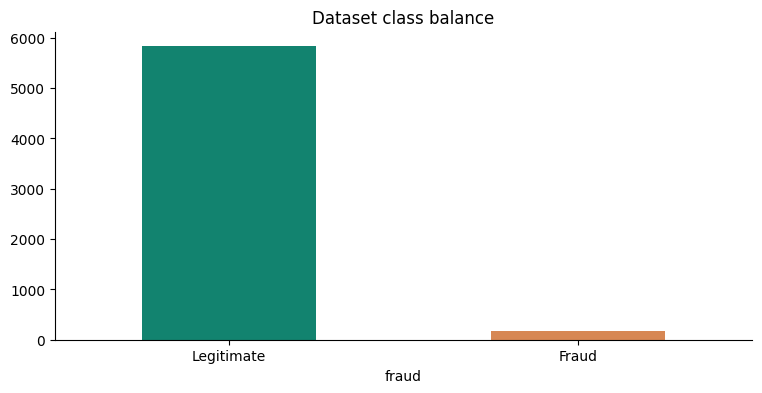

In [2]:
from app.services.model import dataset, splits, train_models, metrics
from app.domain.schema import FEATURES
import pandas as pd
import numpy as np
x, y = dataset()
# Optionally analyze a labelled CSV instead of the synthetic demonstration.
import os
from app.services.data import load_csv
custom_csv = os.getenv('SENTINEL_ANALYSIS_CSV')
if custom_csv:
    x, y = load_csv(Path(custom_csv).read_text(), labelled=True)
display(x.describe().round(2))
y.value_counts().sort_index().plot.bar(color=['#12836f','#d78753'], title='Dataset class balance', rot=0)
plt.xticks([0,1], ['Legitimate','Fraud']); plt.show()
print(f'Fraud prevalence: {y.mean():.2%}')

## 2. Leakage controls
60% training, 20% validation, 20% test, stratified with a fixed seed. Scaling is fitted only inside the logistic-regression training pipeline. Model choice uses validation AP; review thresholds maximize validation F1. Test data is used only for final evaluation. Random splits suit this IID simulator; a real deployment requires chronological and customer-group separation.

In [3]:
bundle = train_models(x, y)
assert set(bundle['train_x'].index).isdisjoint(bundle['test_x'].index)
results = pd.DataFrame(bundle['metrics']).T
display(results.drop(columns='confusion_matrix').round(4))
print('Validation AP:', bundle['validation_ap'])
print('Chosen without test-set selection:', bundle['winner'])

Validation AP: {'Logistic Regression': 0.1293431825076902, 'Random Forest': 0.18335668530973426, 'XGBoost': 0.2127309859321823}
Chosen without test-set selection: XGBoost


,precision,recall,f1,roc_auc,average_precision,false_positive_rate,threshold
Logistic Regression,0.162162,0.176471,0.169014,0.758929,0.103771,0.026587,0.84036
Random Forest,0.173913,0.235294,0.2,0.784129,0.150056,0.03259,0.399553
XGBoost,0.139535,0.176471,0.155844,0.804081,0.151824,0.031732,0.150697


## 3. Precision–recall and ROC curves
Average precision is compared with population prevalence. Report both ranking quality and operational false positives; accuracy alone hides minority-class errors.

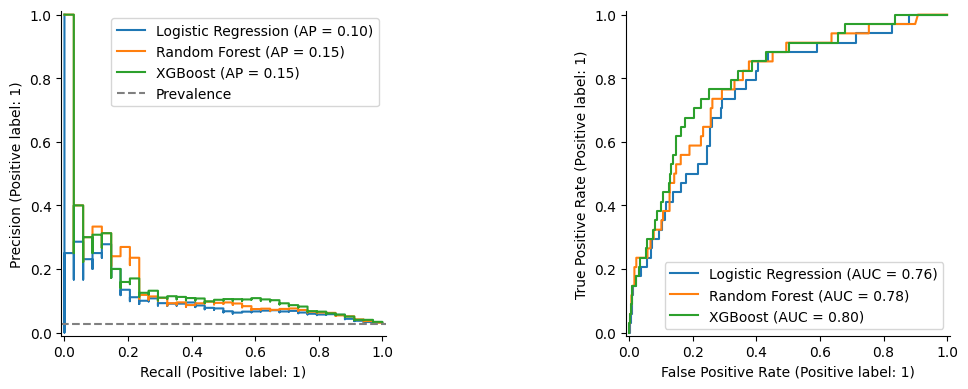

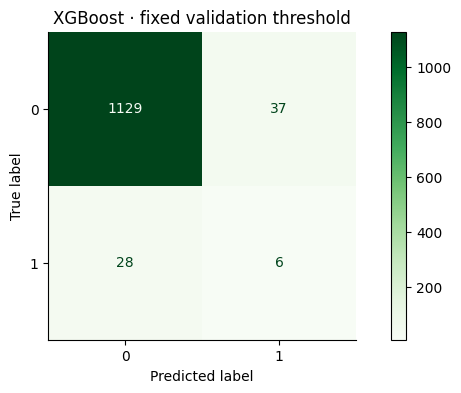

In [4]:
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay, ConfusionMatrixDisplay
fig, axes = plt.subplots(1,2,figsize=(12,4))
for name, model in bundle['models'].items():
    p = model.predict_proba(bundle['test_x'])[:,1]
    PrecisionRecallDisplay.from_predictions(bundle['test_y'],p,name=name,ax=axes[0])
    RocCurveDisplay.from_predictions(bundle['test_y'],p,name=name,ax=axes[1])
axes[0].axhline(bundle['test_y'].mean(),ls='--',color='gray',label='Prevalence'); axes[0].legend(); plt.tight_layout(); plt.show()
name=bundle['winner']; model=bundle['models'][name]
p=model.predict_proba(bundle['test_x'])[:,1]; t=bundle['thresholds'][name]
ConfusionMatrixDisplay.from_predictions(bundle['test_y'],p>=t,cmap='Greens'); plt.title(name+' · fixed validation threshold'); plt.show()

## 4. Threshold trade-offs and uncertainty
The table below is diagnostic, not another model-selection step. Bootstrap confidence intervals reflect only this synthetic test sample; they do not measure population drift or deployment validity.

In [5]:
display(pd.DataFrame([{'cutoff':t, **{k:v for k,v in metrics(bundle['test_y'],p,t).items() if k!='confusion_matrix'}} for t in [.1,.2,.3,.5,.7]]).round(3))
from sklearn.metrics import average_precision_score
rng=np.random.default_rng(23); ytest=bundle['test_y'].to_numpy(); estimates=[]
for _ in range(300):
    ids=rng.integers(0,len(ytest),len(ytest))
    if len(np.unique(ytest[ids]))==2: estimates.append(average_precision_score(ytest[ids],p[ids]))
print('Bootstrap AP 95% interval:',np.quantile(estimates,[.025,.975]))

Bootstrap AP 95% interval: [0.07282972 0.26754321]


,cutoff,precision,recall,f1,roc_auc,average_precision,false_positive_rate,threshold
0,0.1,0.125,0.294,0.175,0.804,0.152,0.060,0.1
1,0.2,0.192,0.147,0.167,0.804,0.152,0.018,0.2
2,0.3,0.300,0.088,0.136,0.804,0.152,0.006,0.3
3,0.5,1.000,0.029,0.057,0.804,0.152,0.000,0.5
4,0.7,0.000,0.000,0.000,0.804,0.152,0.000,0.7


## 5. Explainability with SHAP
Tree SHAP explains the random forest. Contributions are in positive-class probability space. Explanations describe the fitted model, not causal relationships.

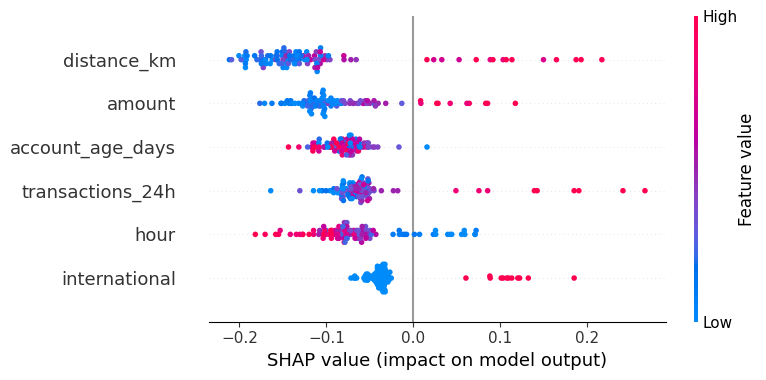

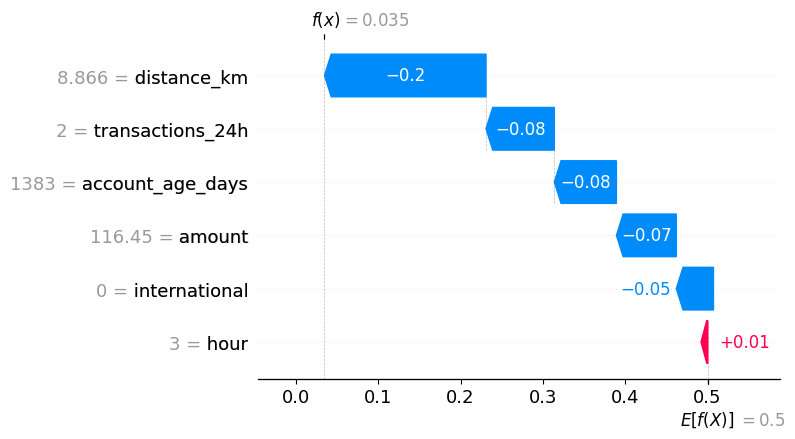

In [6]:
import shap
forest=bundle['models']['Random Forest']
explainer=shap.TreeExplainer(forest)
sample=bundle['test_x'].iloc[:100]
explanation=explainer(sample)
positive=explanation[:,:,1] if explanation.values.ndim==3 else explanation
shap.plots.beeswarm(positive,show=False); plt.tight_layout(); plt.show()
shap.plots.waterfall(positive[0],show=False); plt.tight_layout(); plt.show()

## 6. Model card and next experiment
Intended use: educational transaction triage. Not intended for automated financial decisions. No personal data is included. Next: evaluate a licensed real transaction dataset with temporal splits, entity leakage checks, calibration, subgroup errors, drift monitoring and a cost-sensitive threshold. Do not present these synthetic scores as commercial outcomes.